# Лабораторна 7. Завдання 4 — Dogs vs Cats (пункти 21–26)

Набір Kaggle *Dogs vs Cats*: `train.zip` містить 25 000 фото з мітками в імені файлу
(`cat.0.jpg … cat.12499.jpg`, `dog.0.jpg … dog.12499.jpg`).
`flow_from_directory` вимагає структуру «папка = клас», тому спершу власний скрипт
розкладає набір на **train / val / test** з підпапками `cats/` і `dogs/`.

Середовище і шляхи.

In [1]:
# Визначення середовища та базових шляхів (працює і локально, і в Colab)
import json
import os
import time
from pathlib import Path

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

LAB_ROOT = Path("/content") if IN_COLAB else Path.cwd().parent   # notebooks/ -> dl/lab7
DATA = LAB_ROOT / "data"
MY_IMAGES = LAB_ROOT / "my_images"
RESULTS = LAB_ROOT / "results"
MODELS = LAB_ROOT / "models"
for d in (DATA, RESULTS / "raw", MODELS):
    d.mkdir(parents=True, exist_ok=True)
print("IN_COLAB =", IN_COLAB)
print("LAB_ROOT =", LAB_ROOT)

IN_COLAB = False
LAB_ROOT = C:\uni_year_4\dl\lab7


**Пункт 21, крок 1.** Вихідні дані.

Локально: 25 000 jpg уже розпаковані скриптом `scripts/extract_data.py` у `data/dogs_vs_cats_raw/train`.
У Colab: монтуємо Google Drive і розпаковуємо `dogs-vs-cats.zip` → `train.zip` → `/content/train`
(архів 812 МБ завантажувати через браузер недоцільно).

In [2]:
if IN_COLAB:
    import zipfile
    from google.colab import drive

    drive.mount("/content/drive")
    ZIP_PATH = "/content/drive/MyDrive/dogs-vs-cats.zip"   # змініть, якщо файл в іншій папці
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extract("train.zip", "/content")
    with zipfile.ZipFile("/content/train.zip") as z:
        z.extractall("/content")
    RAW_TRAIN = Path("/content/train")
else:
    RAW_TRAIN = DATA / "dogs_vs_cats_raw" / "train"

files = sorted(os.listdir(RAW_TRAIN))
print(RAW_TRAIN, "->", len(files), "файлів")
print(files[:3], "...", files[-3:])

C:\uni_year_4\dl\lab7\data\dogs_vs_cats_raw\train -> 25000 файлів
['cat.0.jpg', 'cat.1.jpg', 'cat.10.jpg'] ... ['dog.9997.jpg', 'dog.9998.jpg', 'dog.9999.jpg']


**Пункт 21, крок 2.** Скрипт розділення на train / val / test (той самий код, що в
`scripts/prepare_dataset.py`): `create_directory` створює чисту структуру, `copy_images` копіює
файли за діапазоном індексів.

`PER_CLASS_*` задають розмір набору. Повний набір — 8750 / 1875 / 1875 на клас (70/15/15),
на цьому комп'ютері одна епоха триває ≈4.9 хв (замір у `results/raw/timing_probe.json`),
тому прогін зроблено на **повному наборі**; `PER_CLASS_*` дозволяють узяти підмножину.

In [3]:
import shutil

BASE_DIR = DATA / "cats_dogs"
train_dir, val_dir, test_dir = BASE_DIR / "train", BASE_DIR / "val", BASE_DIR / "test"

# Розмір набору: None -> повний набір (70/15/15 від 12500 на клас).
# Замір на цьому CPU: 0.47 с/крок -> ~4.9 хв на епоху при 546 кроках, тобто повний
# набір прийнятний (results/raw/timing_probe.json). Для швидкого прогону можна
# поставити, наприклад, 2000 / 500 / 500.
PER_CLASS_TRAIN = None
PER_CLASS_VAL = None
PER_CLASS_TEST = None


def create_directory(dir_name):
    if os.path.exists(dir_name):
        shutil.rmtree(dir_name)
    os.makedirs(dir_name)
    os.makedirs(os.path.join(dir_name, "cats"))
    os.makedirs(os.path.join(dir_name, "dogs"))


def copy_images(start_index, end_index, source_dir, dest_dir):
    for i in range(start_index, end_index):
        shutil.copy2(os.path.join(source_dir, f"cat.{i}.jpg"), os.path.join(dest_dir, "cats"))
        shutil.copy2(os.path.join(source_dir, f"dog.{i}.jpg"), os.path.join(dest_dir, "dogs"))


if PER_CLASS_TRAIN is None:
    nb_images, val_portion, test_portion = 12500, 0.15, 0.15
    n_train = int(nb_images * (1 - val_portion - test_portion))
    n_val = int(nb_images * (1 - test_portion)) - n_train
    n_test = nb_images - n_train - n_val
else:
    n_train, n_val, n_test = PER_CLASS_TRAIN, PER_CLASS_VAL, PER_CLASS_TEST

need_split = not all((train_dir / c).is_dir() for c in ("cats", "dogs")) or \
    len(list((train_dir / "cats").glob("*.jpg"))) != n_train

if need_split:
    for d in (train_dir, val_dir, test_dir):
        create_directory(d)
    copy_images(0, n_train, RAW_TRAIN, train_dir)
    copy_images(n_train, n_train + n_val, RAW_TRAIN, val_dir)
    copy_images(n_train + n_val, n_train + n_val + n_test, RAW_TRAIN, test_dir)
print(f"На клас: train={n_train}, val={n_val}, test={n_test}")

На клас: train=8750, val=1875, test=1875


**Пункт 21, результат №5.** Структура каталогів із кількістю файлів.

In [4]:
tree_lines = [str(BASE_DIR)]
for si, split in enumerate(("train", "val", "test")):
    s_last = si == 2
    tree_lines.append(f"{'└──' if s_last else '├──'} {split}/")
    for ci, cls in enumerate(("cats", "dogs")):
        c_last = ci == 1
        n = len(list((BASE_DIR / split / cls).glob("*.jpg")))
        tree_lines.append(f"{'    ' if s_last else '│   '}{'└──' if c_last else '├──'} {cls}/  {n} файлів")
tree = "\n".join(tree_lines)
print(tree)
(RESULTS / "dir_tree.txt").write_text(tree, encoding="utf-8")

C:\uni_year_4\dl\lab7\data\cats_dogs
├── train/
│   ├── cats/  8750 файлів
│   └── dogs/  8750 файлів
├── val/
│   ├── cats/  1875 файлів
│   └── dogs/  1875 файлів
└── test/
    ├── cats/  1875 файлів
    └── dogs/  1875 файлів


228

Приклади зображень із навчального набору.

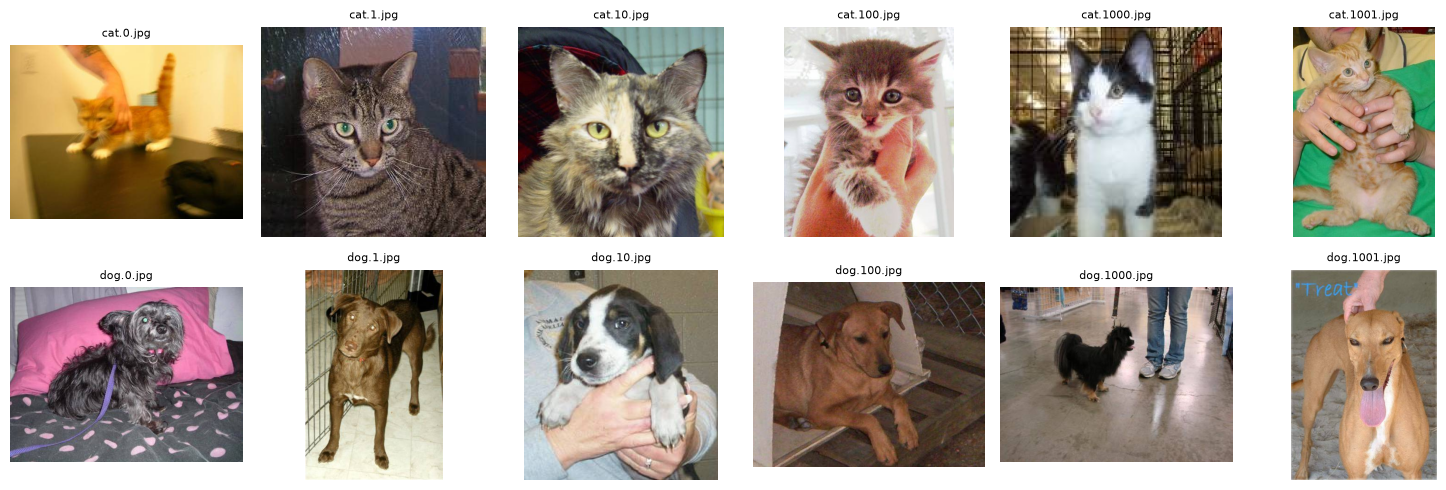

In [5]:
import matplotlib.pyplot as plt
from tensorflow.keras.utils import load_img

fig, axes = plt.subplots(2, 6, figsize=(15, 5))
for row, cls in enumerate(("cats", "dogs")):
    names = sorted(os.listdir(train_dir / cls))[:6]
    for ax, n in zip(axes[row], names):
        ax.imshow(load_img(train_dir / cls / n))
        ax.set_title(n, fontsize=8)
        ax.axis("off")
plt.tight_layout()
plt.savefig(RESULTS / "task4_dataset_sample.png", dpi=90, bbox_inches="tight")
plt.show()

**Пункт 22.** Генератори `ImageDataGenerator(rescale=1/255)`, усі зображення → 150×150.
Для тестового генератора `shuffle=False`, щоб порядок передбачень збігався з мітками.

In [6]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

img_width, img_height = 150, 150
input_shape = (img_width, img_height, 3)
batch_size = 32
epochs = 15

datagen = ImageDataGenerator(rescale=1. / 255)
train_generator = datagen.flow_from_directory(str(train_dir), target_size=(img_width, img_height),
                                              batch_size=batch_size, class_mode="binary")
val_generator = datagen.flow_from_directory(str(val_dir), target_size=(img_width, img_height),
                                            batch_size=batch_size, class_mode="binary")
test_generator = datagen.flow_from_directory(str(test_dir), target_size=(img_width, img_height),
                                             batch_size=batch_size, class_mode="binary", shuffle=False)
print("Класи:", train_generator.class_indices)
nb_train, nb_val, nb_test = train_generator.samples, val_generator.samples, test_generator.samples

Found 17500 images belonging to 2 classes.


Found 3750 images belonging to 2 classes.


Found 3750 images belonging to 2 classes.


Класи: {'cats': 0, 'dogs': 1}


**Пункт 23.** Архітектура з лекції:
3 × (Conv2D + MaxPooling) → Flatten → Dense(64, relu) → Dropout(0.5) → Dense(1, sigmoid).
Функцію винесено окремо, щоб створити дві однакові моделі для порівняння оптимізаторів.

In [7]:
from tensorflow.keras.layers import Activation, Conv2D, Dense, Dropout, Flatten, MaxPooling2D
from tensorflow.keras.models import Sequential


def build_cnn():
    model = Sequential()
    model.add(Conv2D(32, (3, 3), input_shape=input_shape))
    model.add(Activation("relu"))
    model.add(MaxPooling2D(pool_size=(2, 2)))
    model.add(Conv2D(32, (3, 3)))
    model.add(Activation("relu"))
    model.add(MaxPooling2D(pool_size=(2, 2)))
    model.add(Conv2D(64, (3, 3)))
    model.add(Activation("relu"))
    model.add(MaxPooling2D(pool_size=(2, 2)))
    model.add(Flatten())
    model.add(Dense(64))
    model.add(Activation("relu"))
    model.add(Dropout(0.5))
    model.add(Dense(1))
    model.add(Activation("sigmoid"))
    return model


cnn = build_cnn()
cnn.summary()
summary_lines = []
cnn.summary(print_fn=lambda s: summary_lines.append(s))
(RESULTS / "raw" / "task4_model_summary.txt").write_text("\n".join(summary_lines), encoding="utf-8")
total_params = int(cnn.count_params())
print("Усього параметрів:", total_params)

C:\uni_year_4\dl\lab7\.venv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 148, 148, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 72, 72, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 34, 34, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 18496)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     1,183,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 1)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,212,513 (4.63 MB)

 Trainable params: 1,212,513 (4.63 MB)

 Non-trainable params: 0 (0.00 B)

Усього параметрів: 1212513


**Пункт 24.** Запобігання перенавчанню: `EarlyStopping` зупиняє навчання, якщо `val_loss`
не покращується 3 епохи поспіль, і повертає найкращі ваги; `ModelCheckpoint` зберігає найкращу модель.

In [8]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint


def make_callbacks(name):
    return [EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
            ModelCheckpoint(str(MODELS / f"{name}.keras"), monitor="val_loss", save_best_only=True)]


def plot_history(h, title, out_png):
    plt.figure(figsize=(12, 4))
    for i, (m, name) in enumerate([("accuracy", "Точність"), ("loss", "Втрати")]):
        plt.subplot(1, 2, i + 1)
        plt.plot(range(1, len(h.history[m]) + 1), h.history[m], "o-", label="Навчання")
        plt.plot(range(1, len(h.history[m]) + 1), h.history["val_" + m], "s-", label="Валідація")
        plt.title(f"{name} — {title}")
        plt.xlabel("Епоха")
        plt.legend()
        plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(RESULTS / out_png, dpi=110, bbox_inches="tight")
    plt.show()

**Навчання A: оптимізатор Adam** (як у лекції).

Epoch 1/15


546/546 - 130s - 239ms/step - accuracy: 0.6671 - loss: 0.6018 - val_accuracy: 0.6862 - val_loss: 0.5886


Epoch 2/15


C:\uni_year_4\dl\lab7\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


546/546 - 10s - 18ms/step - accuracy: 0.6875 - loss: 0.5860 - val_accuracy: 0.7035 - val_loss: 0.5614


...

Epoch 11/15


546/546 - 123s - 226ms/step - accuracy: 0.8741 - loss: 0.2909 - val_accuracy: 0.8379 - val_loss: 0.3870


Epoch 12/15


546/546 - 9s - 17ms/step - accuracy: 0.8750 - loss: 0.3296 - val_accuracy: 0.8392 - val_loss: 0.3880


Час навчання (Adam): 13.5 хв


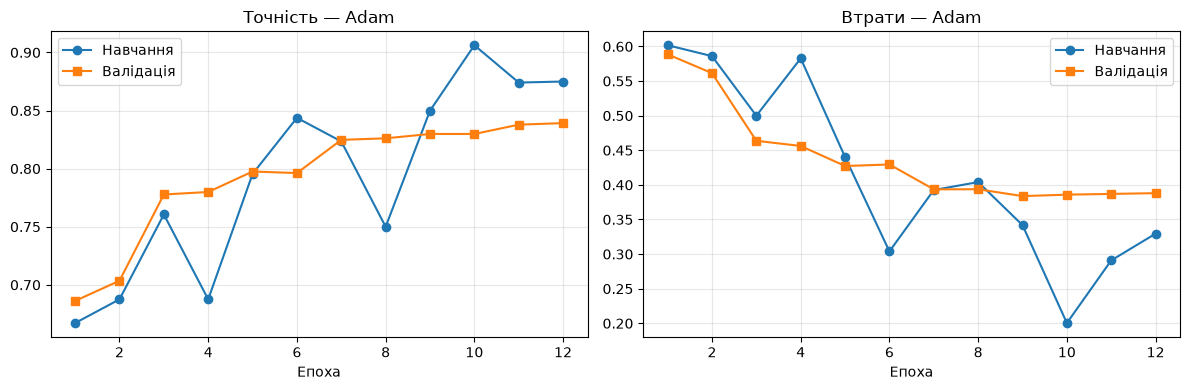

In [9]:
model_adam = build_cnn()
model_adam.compile(loss="binary_crossentropy", optimizer="adam", metrics=["accuracy"])

t0 = time.time()
history_adam = model_adam.fit(train_generator,
                              steps_per_epoch=nb_train // batch_size,
                              epochs=epochs,
                              validation_data=val_generator,
                              validation_steps=nb_val // batch_size,
                              callbacks=make_callbacks("cats_dogs_adam"),
                              verbose=2)
time_adam = time.time() - t0
print(f"Час навчання (Adam): {time_adam / 60:.1f} хв")
plot_history(history_adam, "Adam", "task4_history_adam.png")

**Навчання B: `RMSprop(learning_rate=0.001)`** (пункт 24 — чи покращиться якість).

Epoch 1/15


546/546 - 124s - 227ms/step - accuracy: 0.6500 - loss: 0.6190 - val_accuracy: 0.7217 - val_loss: 0.5529


Epoch 2/15


546/546 - 9s - 17ms/step - accuracy: 0.7188 - loss: 0.5334 - val_accuracy: 0.7300 - val_loss: 0.5386


Epoch 3/15


...

Epoch 14/15


546/546 - 9s - 17ms/step - accuracy: 0.7500 - loss: 0.3827 - val_accuracy: 0.8384 - val_loss: 0.3706


Epoch 15/15


546/546 - 122s - 223ms/step - accuracy: 0.8907 - loss: 0.2683 - val_accuracy: 0.8507 - val_loss: 0.3703


Час навчання (RMSprop): 17.4 хв


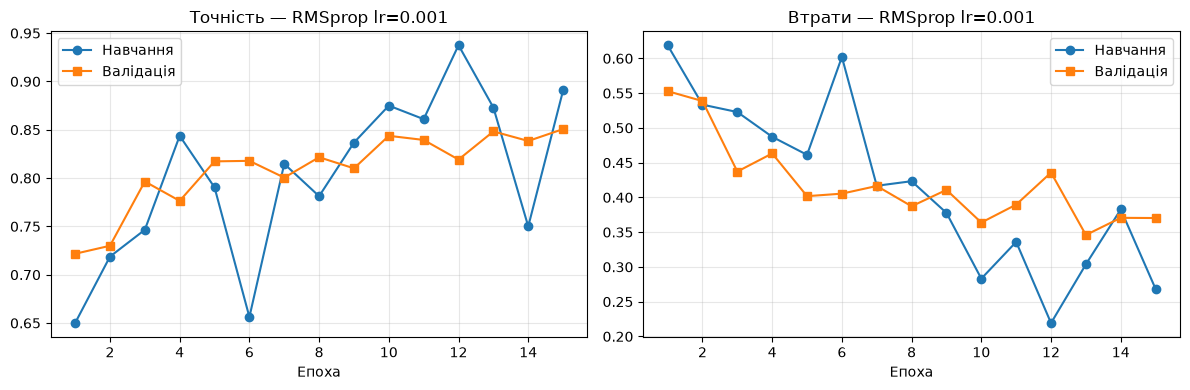

In [10]:
from tensorflow.keras.optimizers import RMSprop

model_rms = build_cnn()
model_rms.compile(loss="binary_crossentropy", optimizer=RMSprop(learning_rate=0.001),
                  metrics=["accuracy"])

t0 = time.time()
history_rms = model_rms.fit(train_generator,
                            steps_per_epoch=nb_train // batch_size,
                            epochs=epochs,
                            validation_data=val_generator,
                            validation_steps=nb_val // batch_size,
                            callbacks=make_callbacks("cats_dogs_rmsprop"),
                            verbose=2)
time_rms = time.time() - t0
print(f"Час навчання (RMSprop): {time_rms / 60:.1f} хв")
plot_history(history_rms, "RMSprop lr=0.001", "task4_history_rmsprop.png")

**Пункт 24.** Оцінка на тестовому наборі — ці зображення модель не бачила ні під час
навчання, ні під час вибору ваг. Кращу модель зберігаємо і використовуємо далі.

In [11]:
test_generator.reset()
loss_adam, acc_adam = model_adam.evaluate(test_generator, verbose=0)
test_generator.reset()
loss_rms, acc_rms = model_rms.evaluate(test_generator, verbose=0)
print(f"Test accuracy  Adam: {acc_adam * 100:.2f}%   RMSprop(0.001): {acc_rms * 100:.2f}%")
print(f"Test loss      Adam: {loss_adam:.4f}   RMSprop(0.001): {loss_rms:.4f}")

best_name = "Adam" if acc_adam >= acc_rms else "RMSprop(0.001)"
model = model_adam if acc_adam >= acc_rms else model_rms
model.save(MODELS / "cats_dogs_best.keras")
print("Далі використовуємо:", best_name)

Test accuracy  Adam: 82.67%   RMSprop(0.001): 84.24%
Test loss      Adam: 0.3971   RMSprop(0.001): 0.3644
Далі використовуємо: RMSprop(0.001)


Матриця помилок і звіт по класах на тестовому наборі.

[[1584  291]
 [ 300 1575]]
              precision    recall  f1-score   support

        cats       0.84      0.84      0.84      1875
        dogs       0.84      0.84      0.84      1875

    accuracy                           0.84      3750
   macro avg       0.84      0.84      0.84      3750
weighted avg       0.84      0.84      0.84      3750



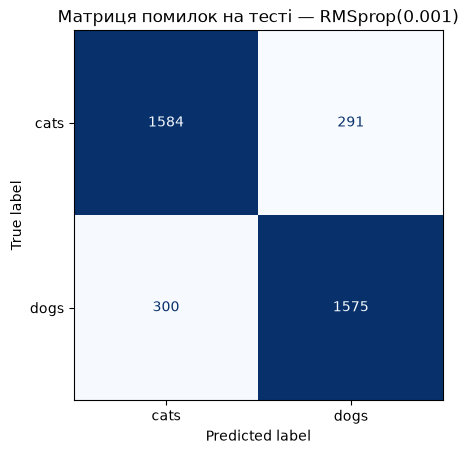

In [12]:
import numpy as np
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix

test_generator.reset()
y_prob = model.predict(test_generator, verbose=0).ravel()
y_pred = (y_prob > 0.5).astype(int)
y_true = test_generator.classes

cm = confusion_matrix(y_true, y_pred)
report = classification_report(y_true, y_pred, target_names=["cats", "dogs"])
print(cm)
print(report)
(RESULTS / "raw" / "task4_classification_report.txt").write_text(
    f"Найкраща модель: {best_name}\n\n{cm}\n\n{report}", encoding="utf-8")

ConfusionMatrixDisplay(cm, display_labels=["cats", "dogs"]).plot(cmap="Blues", colorbar=False)
plt.title(f"Матриця помилок на тесті — {best_name}")
plt.savefig(RESULTS / "task4_confusion_matrix.png", dpi=110, bbox_inches="tight")
plt.show()

**Пункт 23 (друга частина).** Розпізнавання власних зображень: по 10 котів і собак.
Правильна відповідь береться з префікса імені файлу (`cat_*`, `dog_*`). Клас 1 = *dogs*.

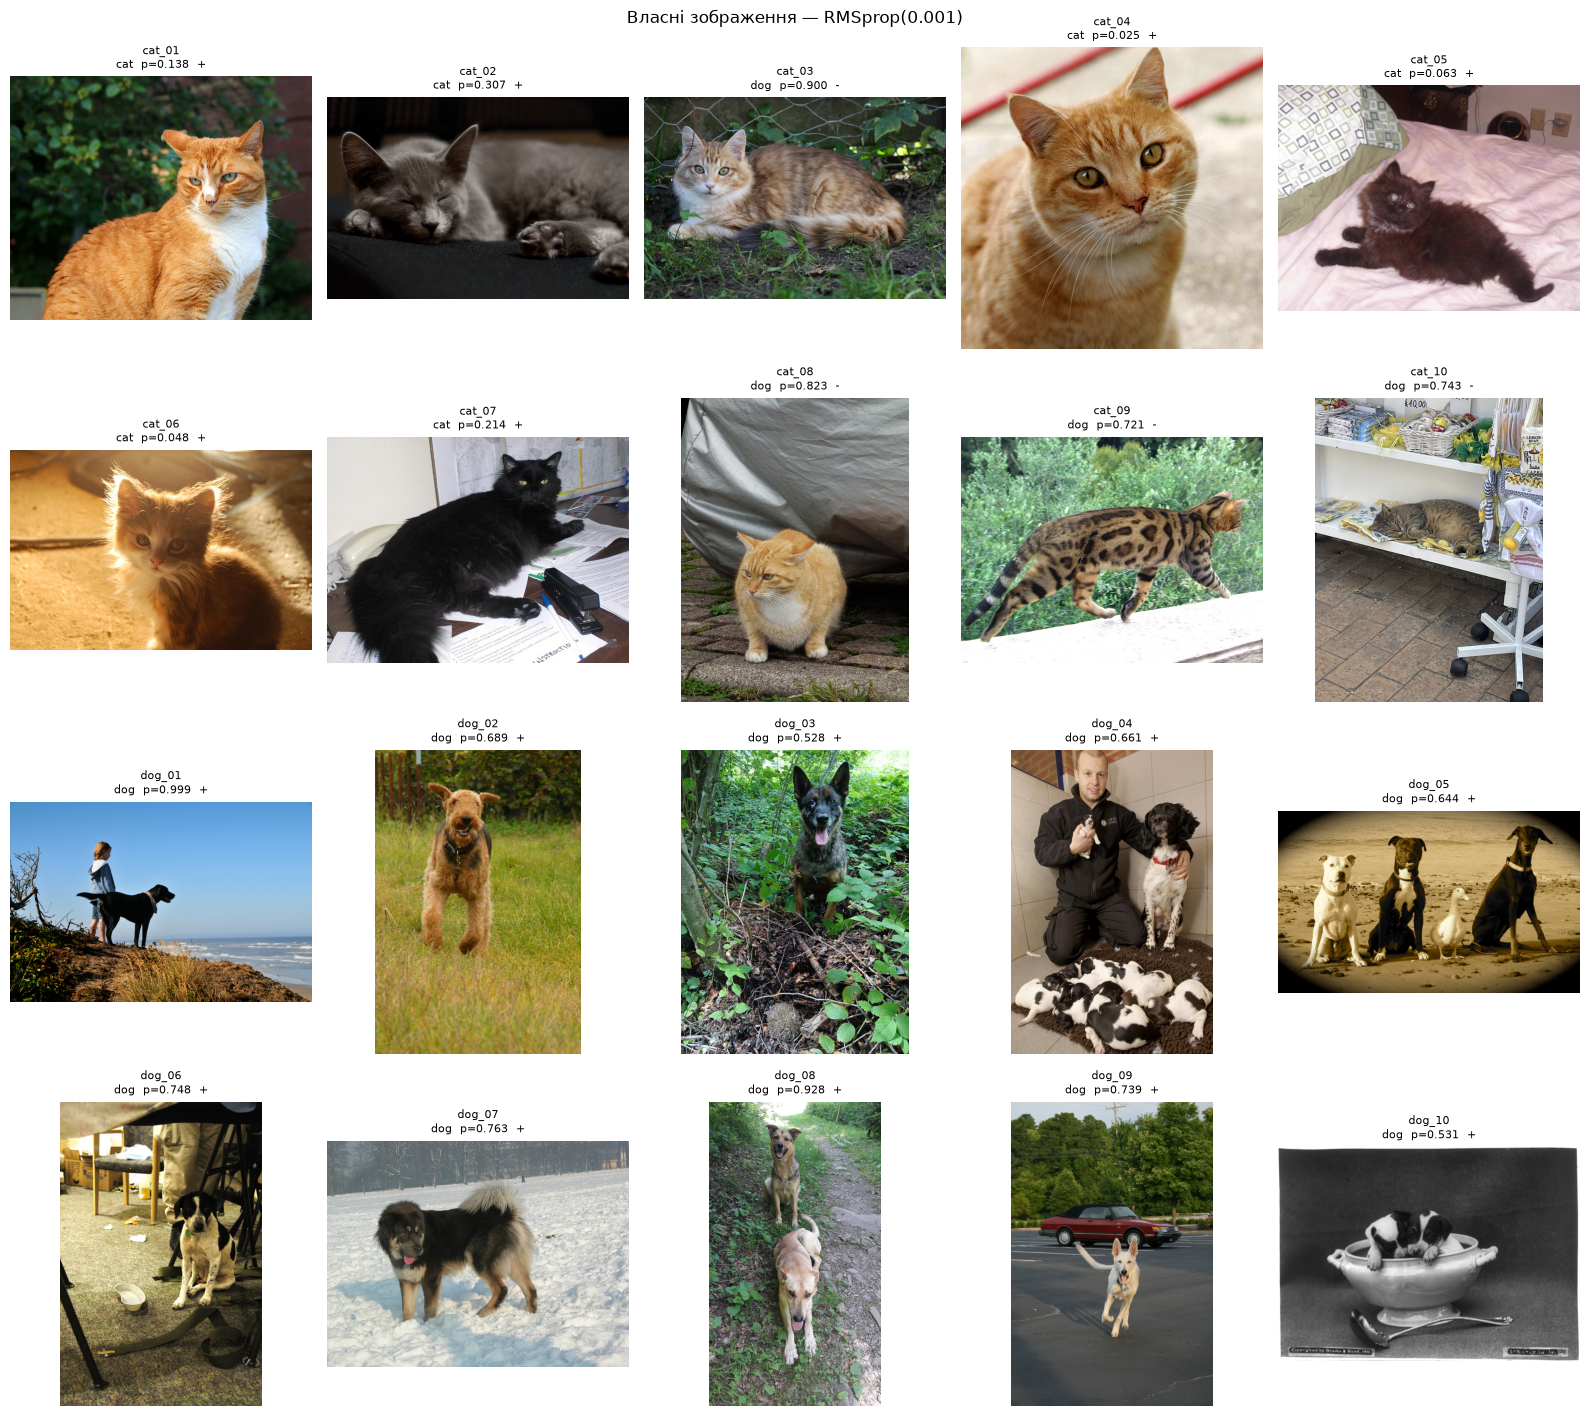

{'file': 'cat_01.jpg', 'prob_dog': 0.1384, 'predicted': 'cat', 'expected': 'cat', 'correct': True}
{'file': 'cat_02.jpg', 'prob_dog': 0.3071, 'predicted': 'cat', 'expected': 'cat', 'correct': True}
{'file': 'cat_03.jpg', 'prob_dog': 0.9003, 'predicted': 'dog', 'expected': 'cat', 'correct': False}
{'file': 'cat_04.jpg', 'prob_dog': 0.0249, 'predicted': 'cat', 'expected': 'cat', 'correct': True}
{'file': 'cat_05.jpg', 'prob_dog': 0.0631, 'predicted': 'cat', 'expected': 'cat', 'correct': True}
{'file': 'cat_06.jpg', 'prob_dog': 0.0478, 'predicted': 'cat', 'expected': 'cat', 'correct': True}
{'file': 'cat_07.jpg', 'prob_dog': 0.2141, 'predicted': 'cat', 'expected': 'cat', 'correct': True}
{'file': 'cat_08.jpg', 'prob_dog': 0.8232, 'predicted': 'dog', 'expected': 'cat', 'correct': False}
{'file': 'cat_09.jpg', 'prob_dog': 0.7206, 'predicted': 'dog', 'expected': 'cat', 'correct': False}
{'file': 'cat_10.jpg', 'prob_dog': 0.743, 'predicted': 'dog', 'expected': 'cat', 'correct': False}
{'file'

In [13]:
from tensorflow.keras.utils import img_to_array, load_img


def own_image_paths(folder_name):
    """Локально — з my_images/<folder>, у Colab — через files.upload()."""
    if IN_COLAB:
        from google.colab import files
        target = Path("/content/my_images") / folder_name
        target.mkdir(parents=True, exist_ok=True)
        print("Оберіть власні зображення:")
        for fn, data in files.upload().items():
            (target / fn).write_bytes(data)
    else:
        target = MY_IMAGES / folder_name
    return sorted(p for p in target.iterdir() if p.suffix.lower() in {".jpg", ".jpeg", ".png"})


def predict_images(model, paths, title, out_png):
    cols = 5
    rows = (len(paths) + cols - 1) // cols
    plt.figure(figsize=(cols * 3.2, rows * 3.6))
    records = []
    for i, p in enumerate(paths):
        img = load_img(p, target_size=(img_width, img_height))
        x = np.expand_dims(img_to_array(img) / 255.0, axis=0)
        prob = float(model.predict(x, verbose=0)[0][0])
        label = "dog" if prob > 0.5 else "cat"
        # для обрізаних файлів клас береться з імені оригіналу (crop_cat_... -> cat)
        exp = "cat" if p.stem.replace("crop_", "").startswith("cat") else "dog"
        ok = label == exp
        records.append({"file": p.name, "prob_dog": round(prob, 4), "predicted": label,
                        "expected": exp, "correct": ok})
        ax = plt.subplot(rows, cols, i + 1)
        ax.axis("off")
        ax.imshow(load_img(p))
        ax.set_title(f"{p.stem[:20]}\n{label}  p={prob:.3f}  {'+' if ok else '-'}", fontsize=8)
    plt.suptitle(title)
    plt.tight_layout()
    plt.savefig(RESULTS / out_png, dpi=110, bbox_inches="tight")
    plt.show()
    for r in records:
        print(r)
    print(f"\nПравильно: {sum(r['correct'] for r in records)} з {len(records)}")
    return records


paths_my = own_image_paths("task4_cats_dogs")
records_my = predict_images(model, paths_my, f"Власні зображення — {best_name}",
                            "task4_predictions_my.png")

**Пункт 25.** Складні зображення: тварина мала відносно кадру, фон строкатий
(дерево, трава, каміння, сніг, людина поруч). Шукаємо ті, які модель розпізнає **неправильно**.

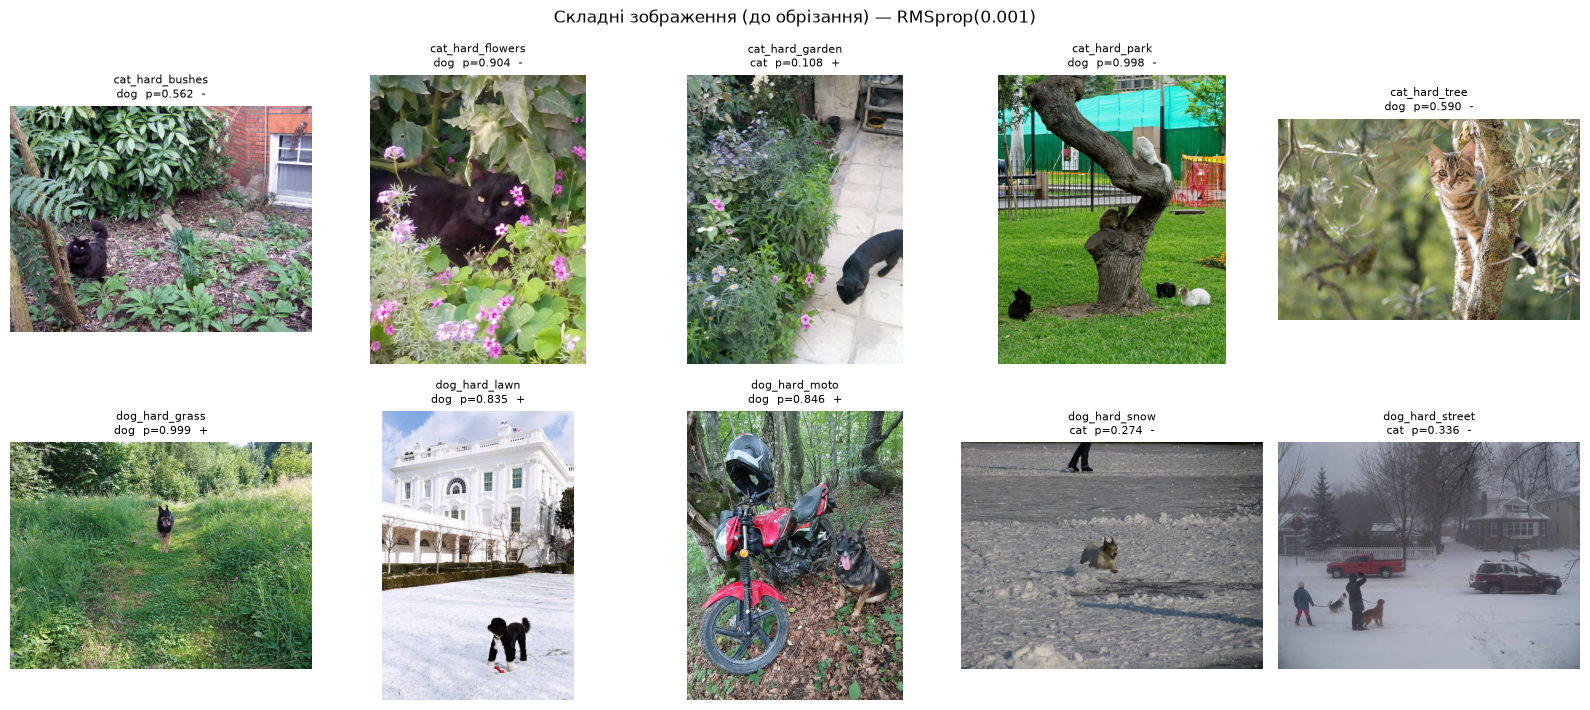

{'file': 'cat_hard_bushes.jpg', 'prob_dog': 0.562, 'predicted': 'dog', 'expected': 'cat', 'correct': False}
{'file': 'cat_hard_flowers.jpg', 'prob_dog': 0.9042, 'predicted': 'dog', 'expected': 'cat', 'correct': False}
{'file': 'cat_hard_garden.jpg', 'prob_dog': 0.1084, 'predicted': 'cat', 'expected': 'cat', 'correct': True}
{'file': 'cat_hard_park.jpg', 'prob_dog': 0.9983, 'predicted': 'dog', 'expected': 'cat', 'correct': False}
{'file': 'cat_hard_tree.jpg', 'prob_dog': 0.5902, 'predicted': 'dog', 'expected': 'cat', 'correct': False}
{'file': 'dog_hard_grass.jpg', 'prob_dog': 0.9991, 'predicted': 'dog', 'expected': 'dog', 'correct': True}
{'file': 'dog_hard_lawn.jpg', 'prob_dog': 0.8349, 'predicted': 'dog', 'expected': 'dog', 'correct': True}
{'file': 'dog_hard_moto.jpg', 'prob_dog': 0.8464, 'predicted': 'dog', 'expected': 'dog', 'correct': True}
{'file': 'dog_hard_snow.jpg', 'prob_dog': 0.2741, 'predicted': 'cat', 'expected': 'dog', 'correct': False}
{'file': 'dog_hard_street.jpg', 'p

In [14]:
paths_hard = own_image_paths("task4_hard")
records_hard = predict_images(model, paths_hard, f"Складні зображення (до обрізання) — {best_name}",
                              "task4_predictions_hard.png")
wrong = [r for r in records_hard if not r["correct"]]
print("\nРозпізнано неправильно:", len(wrong), "з", len(records_hard))
for r in wrong:
    print("  ", r["file"], r["expected"], "->", r["predicted"], f"p_dog={r['prob_dog']}")

**Пункт 26.** Обрізання неправильно розпізнаних зображень так, щоб тварина була в центрі
без зайвого фону, і повторне розпізнавання. Рамки підібрані вручну за переглядом зображень
(`scripts/crop_boxes.json`); якщо рамки немає — береться центральний кроп 55 % кадру.

cat_hard_bushes.jpg: (800, 600) -> рамка (100, 300, 290, 500)
cat_hard_flowers.jpg: (960, 1280) -> рамка (180, 420, 680, 860)
cat_hard_park.jpg: (960, 1218) -> рамка (740, 850, 960, 1040)
cat_hard_tree.jpg: (960, 640) -> рамка (460, 50, 670, 480)
dog_hard_snow.jpg: (960, 720) -> рамка (360, 275, 530, 440)
dog_hard_street.jpg: (960, 721) -> рамка (270, 470, 390, 600)


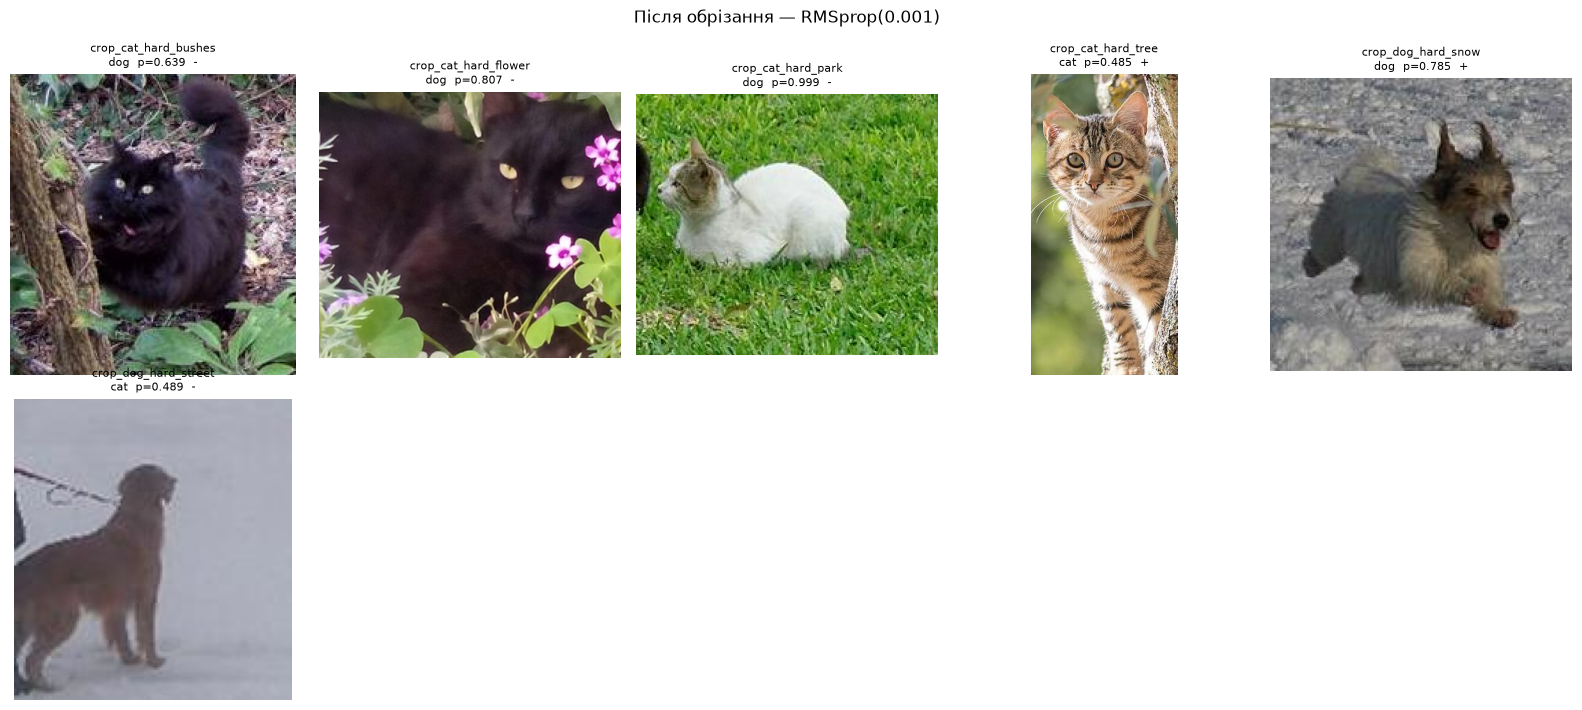

{'file': 'crop_cat_hard_bushes.jpg', 'prob_dog': 0.6386, 'predicted': 'dog', 'expected': 'cat', 'correct': False}
{'file': 'crop_cat_hard_flowers.jpg', 'prob_dog': 0.8074, 'predicted': 'dog', 'expected': 'cat', 'correct': False}
{'file': 'crop_cat_hard_park.jpg', 'prob_dog': 0.9986, 'predicted': 'dog', 'expected': 'cat', 'correct': False}
{'file': 'crop_cat_hard_tree.jpg', 'prob_dog': 0.4851, 'predicted': 'cat', 'expected': 'cat', 'correct': True}
{'file': 'crop_dog_hard_snow.jpg', 'prob_dog': 0.7853, 'predicted': 'dog', 'expected': 'dog', 'correct': True}
{'file': 'crop_dog_hard_street.jpg', 'prob_dog': 0.4889, 'predicted': 'cat', 'expected': 'dog', 'correct': False}

Правильно: 2 з 6


In [15]:
from PIL import Image

CROPPED_DIR = MY_IMAGES / "task4_cropped"
CROPPED_DIR.mkdir(parents=True, exist_ok=True)

boxes_file = LAB_ROOT / "scripts" / "crop_boxes.json"
CROP_BOXES = json.loads(boxes_file.read_text(encoding="utf-8")) if boxes_file.exists() else {}


def crop_box_for(path):
    """Рамка (left, top, right, bottom) у пікселях оригіналу."""
    if path.name in CROP_BOXES:
        return tuple(CROP_BOXES[path.name])
    w, h = Image.open(path).size          # запасний варіант: центральні 55 %
    cw, ch = int(w * 0.55), int(h * 0.55)
    return ((w - cw) // 2, (h - ch) // 2, (w + cw) // 2, (h + ch) // 2)


cropped_paths = []
for r in wrong:
    src = next(p for p in paths_hard if p.name == r["file"])
    box = crop_box_for(src)
    dst = CROPPED_DIR / ("crop_" + src.name)
    Image.open(src).convert("RGB").crop(box).save(dst)
    cropped_paths.append(dst)
    print(f"{src.name}: {Image.open(src).size} -> рамка {box}")

if cropped_paths:
    records_crop = predict_images(model, cropped_paths, f"Після обрізання — {best_name}",
                                  "task4_predictions_cropped.png")
else:
    records_crop = []
    print("Неправильно розпізнаних складних зображень немає — обрізати нічого.")

Збереження всіх чисел завдання 4 для звіту.

In [16]:
metrics = {
    "task": "task4_dogs_vs_cats",
    "subset": {"train_per_class": n_train, "val_per_class": n_val, "test_per_class": n_test,
               "full_dataset": PER_CLASS_TRAIN is None},
    "input_size": [img_width, img_height],
    "batch_size": batch_size,
    "epochs_planned": epochs,
    "samples": {"train": int(nb_train), "val": int(nb_val), "test": int(nb_test)},
    "class_indices": train_generator.class_indices,
    "total_params": total_params,
    "adam": {
        "epochs_done": len(history_adam.history["accuracy"]),
        "train_time_sec": round(time_adam, 1),
        "history": {k: [round(float(v), 4) for v in vals] for k, vals in history_adam.history.items()},
        "test_accuracy": round(float(acc_adam), 4), "test_loss": round(float(loss_adam), 4),
    },
    "rmsprop": {
        "epochs_done": len(history_rms.history["accuracy"]),
        "train_time_sec": round(time_rms, 1),
        "history": {k: [round(float(v), 4) for v in vals] for k, vals in history_rms.history.items()},
        "test_accuracy": round(float(acc_rms), 4), "test_loss": round(float(loss_rms), 4),
    },
    "best_model": best_name,
    "confusion_matrix": cm.tolist(),
    "own_images": records_my,
    "hard_images": records_hard,
    "cropped_images": records_crop,
}
(RESULTS / "raw" / "task4.json").write_text(json.dumps(metrics, ensure_ascii=False, indent=2),
                                            encoding="utf-8")
print("Збережено results/raw/task4.json")

Збережено results/raw/task4.json
